In [2]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from scipy.stats import norm

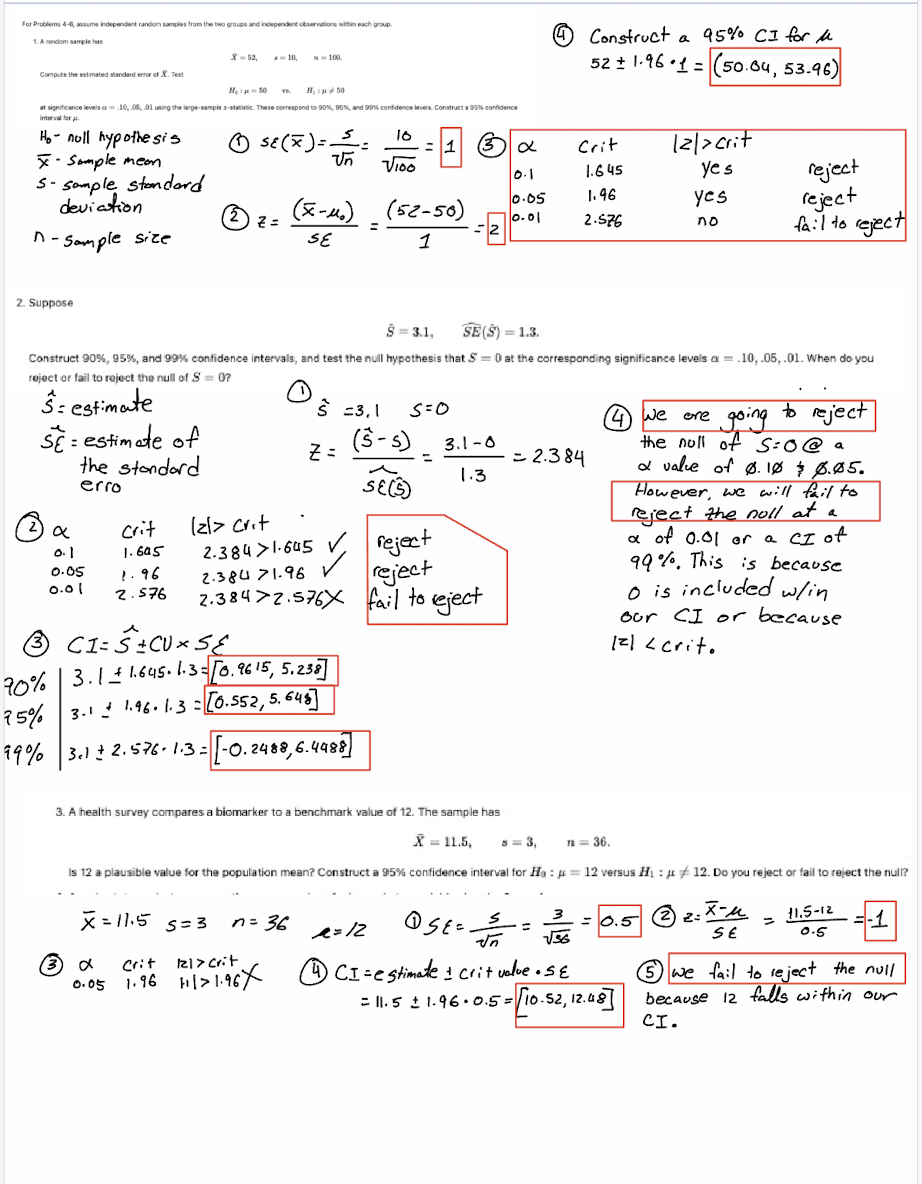

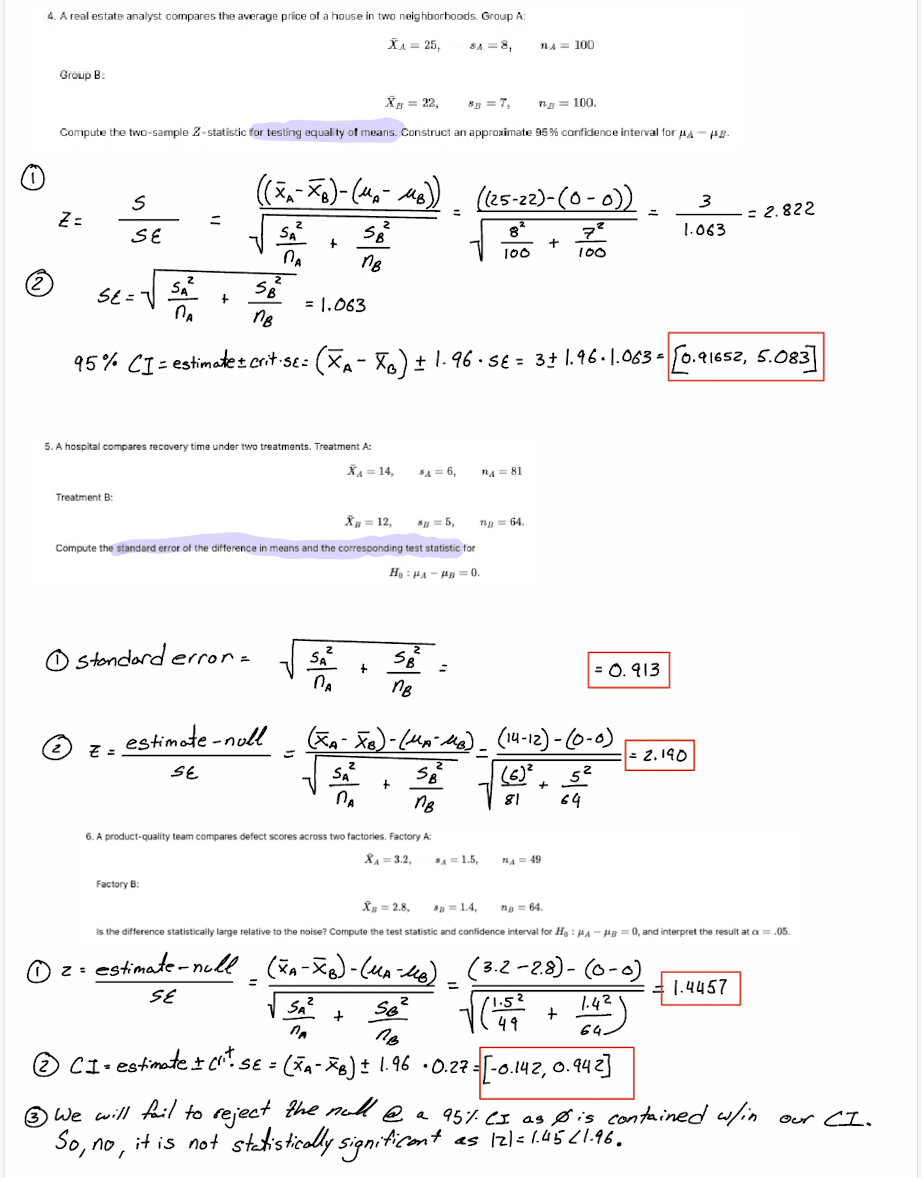

In [3]:
df = pd.read_csv('./data/ames_prices.csv')
df['Central_Air_Indicator'] = (df['Central.Air'] == 'Y').astype(int)
Portion_of_AC = df['Central_Air_Indicator'].mean()
Portion_of_AC

np.float64(0.9331058020477816)

In [4]:
R = 2_000
seed = 12
rng = np.random.default_rng(12)
results = []
for t in range(R):
    resample = df['Central_Air_Indicator'].sample(n = len(df['Central_Air_Indicator']), replace = True, random_state = rng)
    results.append(resample.mean())

print(f" The seed is {seed} and the number of bootstrap replications is {R}")

 The seed is 12 and the number of bootstrap replications is 2000


In [5]:
Bootstrap_SE = np.std(results, ddof=1)
print(f" The Bootstrap Standard Error is {Bootstrap_SE}")

 The Bootstrap Standard Error is 0.0046835514977476836


In [6]:
ci90CV = 1.645
ci95CV = 1.96
ci99CV = 2.576

ci90 = (Portion_of_AC - ci90CV*Bootstrap_SE, Portion_of_AC + ci90CV*Bootstrap_SE)
ci95 = (Portion_of_AC - ci95CV*Bootstrap_SE, Portion_of_AC + ci95CV*Bootstrap_SE)
ci99 = (Portion_of_AC - ci99CV*Bootstrap_SE, Portion_of_AC + ci99CV*Bootstrap_SE)

print(f" The 90% Confidence Interval is {ci90}, The 95% Confidence Interval is {ci95}, The 99% Confidence Interval is {ci99}")

 The 90% Confidence Interval is (np.float64(0.9254013598339866), np.float64(0.9408102442615766)), The 95% Confidence Interval is (np.float64(0.9239260411121961), np.float64(0.9422855629833671)), The 99% Confidence Interval is (np.float64(0.9210409733895836), np.float64(0.9451706307059796))


# 7E
for α = .1 we would reject the null hypothesis as 0.9 does not fall within the 90% Confidence Interval [.9254013598339866,0.9408102442615766]
for α = .05 we would reject the null hypothesis as 0.9 does not fall within the 95% Confidence Interval [.0.9239260411121961,0.0.9422855629833671]
for α = .01 we would reject the null hypothesis as 0.9 does not fall within the 99% Confidence Interval [.9210409733895836,0.0.0.9451706307059796]

We rejected the null hypothesis in every single one of our confidence intervals. This means that the *true* percentage of homes with in Ames with central air does not fall at 90% or below it. Furthermore, the data suggest that the true value actually falls somewhere higher. Likely between 0.92 and 0.94.

In [7]:
a = np.arcsinh(df['area'])
b = np.arcsinh(df['price'])
q8 = a.corr(b)
print(f"Correlation between arcsinh(area) and arcsinh(price): {q8}")

Correlation between arcsinh(area) and arcsinh(price): 0.7231661530091358


In [71]:
I = 3_000
seed2 = 18
rng2 = np.random.default_rng(seed2)
results2 = []
for t in range(I):
    s = df[['area', 'price']].sample(n=len(df), replace=True, random_state=rng2)
    results2.append(np.arcsinh(s['area']).corr(np.arcsinh(s['price'])))

print(f" The seed is {seed2} and the number of bootstrap replications is {I}")

 The seed is 18 and the number of bootstrap replications is 3000


In [72]:
Bootstrap_SE_q8b = np.std(results2, ddof = 1)
print(f" The Bootstrap Standard Error for q8b is {Bootstrap_SE_q8b}")

 The Bootstrap Standard Error for q8b is 0.00999070393531921


In [74]:
ci90_q8c = (q8- ci90CV*Bootstrap_SE_q8b, q8 + ci90CV*Bootstrap_SE_q8b)
ci95_q8c = (q8 - ci95CV*Bootstrap_SE_q8b, q8 + ci95CV*Bootstrap_SE_q8b)
ci99_q8c = (q8 - ci99CV*Bootstrap_SE_q8b, q8 + ci99CV*Bootstrap_SE_q8b)

print(f" The 90% Confidence Interval is {ci90_q8c[0]:.4f}, {ci90_q8c[1]:.4f}, The 95% Confidence Interval is {ci95_q8c[0]:.4f}, {ci95_q8c[1]:.4f}, The 99% Confidence Interval is {ci99_q8c[0]:.4f}, {ci99_q8c[1]:.4f}")

 The 90% Confidence Interval is 0.7067, 0.7396, The 95% Confidence Interval is 0.7036, 0.7427, The 99% Confidence Interval is 0.6974, 0.7489


# 8d
for α = .1 we would reject the null hypothesis as 0 does not fall within the 90% Confidence Interval [0.7067, 0.7396]

for α = .05 we would reject the null hypothesis as 0 does not fall within the 95% Confidence Interval [0.7036, 0.7427]

for α = .01 we would reject the null hypothesis as 0 does not fall within the 99% Confidence Interval [0.6974, 0.7489]

Again we will reject the null hypothesis at all threee confidence levels as 0 does not fall inbetween the interval of any of our Confidence Intervals. Specifically, this means that area and price are positive and strong within the housing prices for Ames. A null hypothesis at p=0 is essentially saying that the two variables (arcsin h of price and area in ames) are not correntaled. We estimated the correlation and then boot strapped in 3000 times. In reality, the true correlation of the arsinh's is likely between 0.6974 and 0.7489

# 8e
Area and price need to remain paired during the resampling because we are calculating the correlation of their arcsinh's. If we did not keep them paired specific house that we are refrencing (this df was organized in columns so each row refers to a specific house in AMES) could become un paired and then we couldnt be measuring the between pirce and area of the same house. If the area and price values were not paired we could be measuring the correlation of two different houses price and area, likely leading to a low correlation.

In [17]:
df_2 = pd.read_csv('./data/metabric.csv')

q9 = df_2['Overall Survival (Months)'].mean()
print(f" The estimated mean recorded time to death or last follow-up is {q9} months.")

 The estimated mean recorded time to death or last follow-up is 129.09429138744105 months.


In [18]:
seed3 = 24
rng3 = np.random.default_rng(seed3)
J = 5_000
results3 = []
for t in range(J):
    results3.append(df_2['Overall Survival (Months)'].sample( n=len(df_2['Overall Survival (Months)']), replace = True, random_state = rng3).mean())

print(f" The seed is {seed3} and the number of bootstrap replications is {J}")

 The seed is 24 and the number of bootstrap replications is 5000


In [19]:
Bootstrap_SE_q9b = np.std(results3, ddof = 1)
print(f" The Bootstrap Standard Error for q9b is {Bootstrap_SE_q9b}")


 The Bootstrap Standard Error for q9b is 2.1570153239231575


In [76]:
ci90_q9c = (q9- ci90CV*Bootstrap_SE_q9b, q9 + ci90CV*Bootstrap_SE_q9b)
ci95_q9c = (q9 - ci95CV*Bootstrap_SE_q9b, q9 + ci95CV*Bootstrap_SE_q9b)
ci99_q9c = (q9 - ci99CV*Bootstrap_SE_q9b, q9 + ci99CV*Bootstrap_SE_q9b)

ci90_q9c_years = ((q9- ci90CV*Bootstrap_SE_q9b)/12 , (q9 + ci90CV*Bootstrap_SE_q9b)/12)
ci95_q9c_years = ((q9 - ci95CV*Bootstrap_SE_q9b)/12 , (q9 + ci95CV*Bootstrap_SE_q9b)/12)
ci99_q9c_years = ((q9 - ci99CV*Bootstrap_SE_q9b)/12 , (q9 + ci99CV*Bootstrap_SE_q9b)/12)

print(f" The 90% Confidence Interval is {ci90_q9c[0]:.4f}, {ci90_q9c[1]:.4f} months, The 95% Confidence Interval is {ci95_q9c[0]:.4f}, {ci95_q9c[1]:.4f} months , The 99% Confidence Interval is {ci99_q9c[0]:.4f}, {ci99_q9c[1]:.4f} months")
print(f" The 90% Confidence Interval is {ci90_q9c_years[0]:.4f}, {ci90_q9c_years[1]:.4f} years, The 95% Confidence Interval is {ci95_q9c_years[0]:.4f}, {ci95_q9c_years[1]:.4f} years , The 99% Confidence Interval is {ci99_q9c_years[0]:.4f}, {ci99_q9c_years[1]:.4f} years")

 The 90% Confidence Interval is 125.5460, 132.6426 months, The 95% Confidence Interval is 124.8665, 133.3220 months , The 99% Confidence Interval is 123.5378, 134.6508 months
 The 90% Confidence Interval is 10.4622, 11.0535 years, The 95% Confidence Interval is 10.4055, 11.1102 years , The 99% Confidence Interval is 10.2948, 11.2209 years


# 9d

for α = .1 we would reject the null hypothesis as 120 does not fall within the 90% Confidence Interval [125.5460, 132.6426]

for α = .05 we would reject the null hypothesis as 120 does not fall within the 95% Confidence Interval [124.8665, 133.3220]

for α = .01 we would reject the null hypothesis as 120 does not fall within the 99% Confidence Interval [123.5378, 134.6508]

# 9E
Like other examples at all three signficance value (α=.10,.05,.01) or at every confidence interval we would rejec tthe null hypothesis. This is because 120 months or 10 years falls outside of every confidence value that we have. Even our most expansive confidence intervall (99% - [123.5378, 134.6508] months or 10.2948, 11.2209 years) missees the null hypoethsis by about a third of a year. This means that the mean of the overall survival is likely greater than the 120 months or 10 years.

Our data is right-censored because we do not know the actual death times for all of the paitents. This data sets covers paitents from diagnosis to death or last follow up. Some of the data still list paitents as living becuase we dont have data for them after their last follow-up appointment. This skews our data becuase some paitents did not and we measured the time until they died. Essentially, we are treating two different outcomes as the same for the sake of the data. For living paitents we know that death happens after the last recporded follow-up appointment, but have no data

This being said if we were to calculate the unrestricted mean lifetime of the patients we would need to know when every single patient died even after they survived the diagnosis. We do not have that data and cannot get that data. This forced us to have a restricted mean lifetime estimation and to treat the final follow up date for living patients as the death date. Treating these two different oucomes as the same for the sake of the data forced us to list the mean lifetime as arestricted instead of unrestricted. This is alot of words to say because the esimate of survival time is only covered within the window of the study it has to be restricted. 

In [45]:
df_3 = pd.read_csv('./data/nhanes_data_17_18.csv')

[c for c in df_3.columns if 'Age' in c]


/var/folders/f5/08nzywt924ncr53fp4v435rh0000gn/T/ipykernel_31145/703462107.py:1: DtypeWarning: Columns (142: ServedActiveDutyInUsArmedForces) have mixed types. Specify dtype option on import or set low_memory=False.
  df_3 = pd.read_csv('./data/nhanes_data_17_18.csv')


['AgeStoppedBreastfeedingdays',
 'AgeFirstFedFormuladays',
 'AgeStoppedReceivingFormuladays',
 'AgeStartedOtherFoodbeverage',
 'AgeFirstFedMilkdays',
 'HowOftenDrankMilkAge512',
 'HowOftenDrankMilkAge1317',
 'HowOftenDrankMilkAge1835',
 'AgeWhenToldYouHadHeartAttack',
 'AgeWhenToldYouHadAStroke',
 'Age1StCancerMcq230ADiagnosed',
 'AgeInYearsAtScreening',
 'AgeInMonthsAtScreening0To24Mos',
 'AgeWhenFirstToldYouHadDiabetes',
 'AgeStartedSmokingCigarettesRegularly']

In [61]:
Sleep_precursor = df_3[(df_3['AgeInYearsAtScreening'] >= 18) & (df_3['SleepHoursWeekdaysOrWorkdays'].notna())]['SleepHoursWeekdaysOrWorkdays']
q10 = Sleep_precursor.mean()
print(f" The mean sleep for respondents over 18 and have an observed SleepHoursWeekdaysOrWorkdays is {q10}")


 The mean sleep for respondents over 18 and have an observed SleepHoursWeekdaysOrWorkdays is 7.62124248496994


In [68]:
seed4 = 30
rng3 = np.random.default_rng(seed4)
K = 7_000
results4 = []
for t in range(K):
    resample = Sleep_precursor.sample( n=len(Sleep_precursor), replace = True, random_state = rng3)
    results4.append(resample.mean())

print(f" The seed is {seed4} and the number of bootstrap replications is {K}")

 The seed is 30 and the number of bootstrap replications is 7000


In [77]:
Bootstrap_SE_q10b = np.std(results4, ddof = 1)
print(f" The Bootstrap Standard Error for q10b is {Bootstrap_SE_q10b}")

 The Bootstrap Standard Error for q10b is 0.022344927880294553


In [67]:
ci90_q10c = (q10- ci90CV*Bootstrap_SE_q10b, q10 + ci90CV*Bootstrap_SE_q10b)
ci95_q10c = (q10 - ci95CV*Bootstrap_SE_q10b, q10 + ci95CV*Bootstrap_SE_q10b)
ci99_q10c = (q10 - ci99CV*Bootstrap_SE_q10b, q10 + ci99CV*Bootstrap_SE_q10b)

print(f" The 90% Confidence Interval is {ci90_q10c[0]:.4f}, {ci90_q10c[1]:.4f}, The 95% Confidence Interval is {ci95_q10c[0]:.4f}, {ci95_q10c[1]:.4f}, The 99% Confidence Interval is {ci99_q10c[0]:.4f}, {ci99_q10c[1]:.4f} ")

 The 90% Confidence Interval is 7.5845, 7.6580, The 95% Confidence Interval is 7.5774, 7.6650, The 99% Confidence Interval is 7.5637, 7.6788 


# 10d
for α = .1 we would reject the null hypothesis as 8 does not fall within the 90% Confidence Interval [7.5845, 7.6580]

for α = .05 we would reject the null hypothesis as 8 does not fall within the 95% Confidence Interval [7.5774, 7.6650]

for α = .01 we would reject the null hypothesis as 8 does not fall within the 99% Confidence Interval [7.5637, 7.6788]

In [70]:
practical_calc = (8.0 - 7.62)*60
print(f"The difference between the sample and the null hypothesis is {practical_calc} minutes of sleep")

The difference between the sample and the null hypothesis is 22.799999999999994 minutes of sleep


# 10e

At each confidence interval or significance level, we would reject the null hypothesis. This is because at μ=8 hours does not fall within any of our CI, even our most expansive interval (99% CI).

It is statistically signficant as it does not fall within a a single confidence interval - even with the bootstrap error considered it does not reach any of the confidence intervals.

Practically, it may not be be significant as there is only 23 minutes of sleep seperating our sample from the null hypothesis. However, 7.6 hours still falls within the commonly recommended 7 to 9 hours for adults. Essentially, our sample is large enough that the bootstrap standard error is pretty small (0.022 hours). For this problem, practical and statistical significance do NOT tell the same story.